In [8]:
import sys
sys.path.append("..")
import pandas as pd, numpy as np, lightgbm as lgb
from src.features import FEATURES
from src.metrics import report
val = pd.read_parquet("data/processed/features_val.parquet")
rows = val[(val.Open == 1) & (val.Sales > 0)]
train_df = rows[rows.Date <= "2015-06-18"]
valid_df = rows[(rows.Date >= "2015-06-19") & (rows.Date <= "2015-07-31")]
X_tr, y_tr = train_df[FEATURES], train_df["LogSales"]
X_va, y_va = valid_df[FEATURES], valid_df["LogSales"]

In [10]:
lgb_model = lgb.LGBMRegressor(
n_estimators=5000, learning_rate=0.03, num_leaves=63,
subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
min_child_samples=40, random_state=42, n_jobs=-1)
lgb_model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)],
callbacks=[lgb.early_stopping(100), lgb.log_evaluation(200)])
pred_lgb = np.expm1(lgb_model.predict(X_va)) 
print("best iteration:", lgb_model.best_iteration_)
report("LightGBM", valid_df.Sales, pred_lgb)

/Users/visheshmisra/Desktop/sales-forecasting/venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.019243 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3440
[LightGBM] [Info] Number of data points in the train set: 802942, number of used features: 26
[LightGBM] [Info] Start training from score 8.757218
Training until validation scores don't improve for 100 rounds
[200]	valid_0's l2: 0.0168527
[400]	valid_0's l2: 0.0152326
[600]	valid_0's l2: 0.0145911
[800]	valid_0's l2: 0.0142398
[1000]	valid_0's l2: 0.0139647
[1200]	valid_0's l2: 0.0137771
[1400]	valid_0's l2: 0.0136537
[1600]	valid_0's l2: 0.0135259
[1800]	valid_0's l2: 0.013426
[2000]	valid_0's l2: 0.0133308
[2200]	valid_0's l2: 0.0132548
[2400]	valid_0's l2: 0.013179
[2600]	valid_0's l2: 0.0131276
[2800]	valid_0's l2: 0.0130545
[3000]	valid_0's l2: 0.0130132
[3200]	valid_0's l2: 0.0129892
[3400]	valid_0's l2: 0.0129437
[3600]	val

{'model': 'LightGBM', 'RMSPE': 0.1163, 'MAPE_%': 8.51, 'MAE': 584.1}

In [3]:
import xgboost as xgb
xgb_model = xgb.XGBRegressor(
n_estimators=3000, learning_rate=0.05, max_depth=8, subsample=0.8,
colsample_bytree=0.8, tree_method="hist", early_stopping_rounds=100,
random_state=42, n_jobs=-1)
xgb_model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=200)
pred_xgb = np.expm1(xgb_model.predict(X_va))
report("XGBoost", valid_df.Sales, pred_xgb)

[0]	validation_0-rmse:0.39638
[200]	validation_0-rmse:0.12232
[400]	validation_0-rmse:0.11735
[600]	validation_0-rmse:0.11568
[800]	validation_0-rmse:0.11480
[1000]	validation_0-rmse:0.11398
[1200]	validation_0-rmse:0.11371
[1400]	validation_0-rmse:0.11334
[1600]	validation_0-rmse:0.11315
[1800]	validation_0-rmse:0.11293
[2000]	validation_0-rmse:0.11283
[2200]	validation_0-rmse:0.11270
[2238]	validation_0-rmse:0.11269


{'model': 'XGBoost', 'RMSPE': 0.1161, 'MAPE_%': 8.49, 'MAE': 584.4}

In [4]:
pred_blend = 0.5 * pred_lgb + 0.5 * pred_xgb
report("Blend LGBM + XGB", valid_df.Sales, pred_blend)

{'model': 'Blend LGBM + XGB', 'RMSPE': 0.1156, 'MAPE_%': 8.45, 'MAE': 580.6}

In [6]:
from prophet import Prophet
def prophet_store(store_id):
    s = train_df[train_df.Store == store_id][["Date", "Sales"]]
    s = s.rename(columns={"Date": "ds", "Sales": "y"})
    m = Prophet(weekly_seasonality=True, yearly_seasonality=True,
        daily_seasonality=False)
    m.fit(s)
    fc = m.predict(pd.DataFrame({"ds": pd.date_range("2015-06-19", "2015-07-31")}))
    v = valid_df[valid_df.Store == store_id][["Date", "Sales"]]
    v = v.merge(fc[["ds", "yhat"]], left_on="Date", right_on="ds")
    return v
v1 = prophet_store(1)
print(report("Prophet store 1", v1.Sales, v1.yhat))
mask = (valid_df.Store == 1).values
print(report("LightGBM store 1", valid_df.Sales[mask], pred_lgb[mask]))

10:09:02 - cmdstanpy - INFO - Chain [1] start processing
10:09:04 - cmdstanpy - INFO - Chain [1] done processing


{'model': 'Prophet store 1', 'RMSPE': 0.1707, 'MAPE_%': 15.14, 'MAE': 655.3}
{'model': 'LightGBM store 1', 'RMSPE': 0.0862, 'MAPE_%': 6.93, 'MAE': 297.5}


In [7]:
rows_out = []
for leaves in [31, 63, 127]:
    for lr in [0.03, 0.05]:
        m = lgb.LGBMRegressor(n_estimators=5000, learning_rate=lr, num_leaves=leaves,
subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
random_state=42, n_jobs=-1)
m.fit(X_tr, y_tr, eval_set=[(X_va, y_va)],
callbacks=[lgb.early_stopping(100, verbose=False)])
p = np.expm1(m.predict(X_va))
r = report("leaves=%d lr=%.2f" % (leaves, lr), valid_df.Sales, p)
r["iters"] = m.best_iteration_
rows_out.append(r)
pd.DataFrame(rows_out).sort_values("RMSPE")

/Users/visheshmisra/Desktop/sales-forecasting/venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.017094 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3440
[LightGBM] [Info] Number of data points in the train set: 802942, number of used features: 26
[LightGBM] [Info] Start training from score 8.757218


,model,RMSPE,MAPE_%,MAE,iters
0,leaves=127 lr=0.05,0.1175,8.55,586.6,2758


In [9]:
results = [
    report("Global mean", valid_df.Sales,
           np.full(len(valid_df), train_df.Sales.mean()))
]
recent = train_df[train_df.Date > "2015-04-23"]
base = (recent.groupby(["Store", "DayOfWeek"])["Sales"].mean()
        .rename("predA").reset_index())
baseline_valid = valid_df.merge(base, on=["Store", "DayOfWeek"], how="left")
baseline_valid["predA"] = baseline_valid["predA"].fillna(train_df.Sales.mean())
results.append(report("Store-weekday avg (last 8 wks)", baseline_valid.Sales,
                      baseline_valid.predA))
pred_same_day_last_year = np.expm1(baseline_valid["lag_364"]).fillna(
    baseline_valid["predA"])
results.append(report("Same day last year", baseline_valid.Sales,
                      pred_same_day_last_year))
results.extend([
    report("LightGBM", valid_df.Sales, pred_lgb),
    report("XGBoost", valid_df.Sales, pred_xgb),
    report("Blend LGBM + XGB", valid_df.Sales, pred_blend),
])
final_table = pd.DataFrame(results).sort_values("RMSPE")
final_table.to_csv("reports/model_comparison.csv", index=False)
final_table

,model,RMSPE,MAPE_%,MAE
5,Blend LGBM + XGB,0.1156,8.45,580.6
4,XGBoost,0.1161,8.49,584.4
3,LightGBM,0.1163,8.51,584.1
2,Same day last year,0.1758,12.35,843.5
1,Store-weekday avg (last 8 wks),0.2666,20.25,1284.3
0,Global mean,0.5773,38.16,2242.2


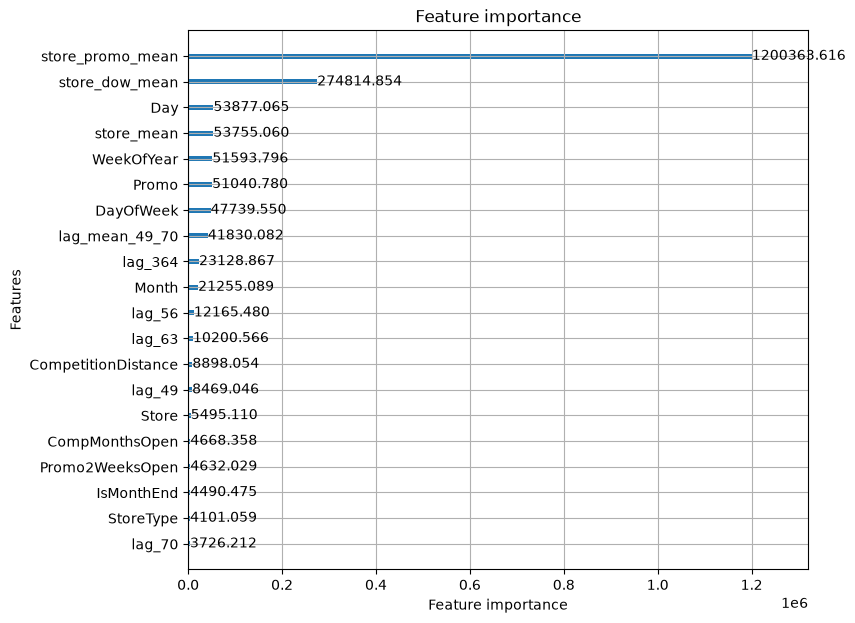

In [10]:
import matplotlib.pyplot as plt
import lightgbm as lgb
lgb.plot_importance(lgb_model, max_num_features=20, importance_type="gain",
figsize=(8, 7))
plt.savefig("reports/figures/04_feature_importance.png", dpi=150, bbox_inches="tight")

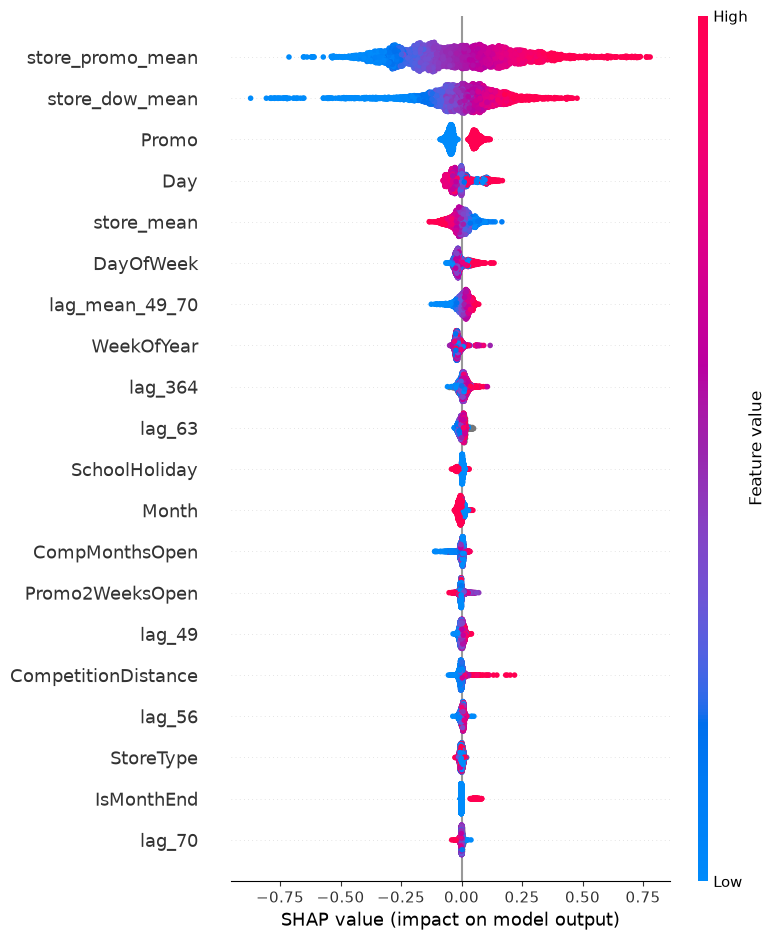

In [12]:
import shap
sample = X_va.sample(5000, random_state=1)
explainer = shap.TreeExplainer(lgb_model)
sv = explainer.shap_values(sample)
shap.summary_plot(sv, sample, show=False)
plt.savefig("reports/figures/05_shap_summary.png", dpi=150, bbox_inches="tight")

StoreType
0    0.085
1    0.087
2    0.087
3    0.084
Name: ape, dtype: float64
DayOfWeek
0    0.085
1    0.078
2    0.078
3    0.089
4    0.078
5    0.104
6    0.104
Name: ape, dtype: float64
Promo
0    0.087
1    0.083
Name: ape, dtype: float64
Store
292     0.559690
909     0.514166
722     0.292087
876     0.289787
274     0.257434
192     0.217255
782     0.202052
1073    0.195144
534     0.192994
286     0.189515
Name: ape, dtype: float64


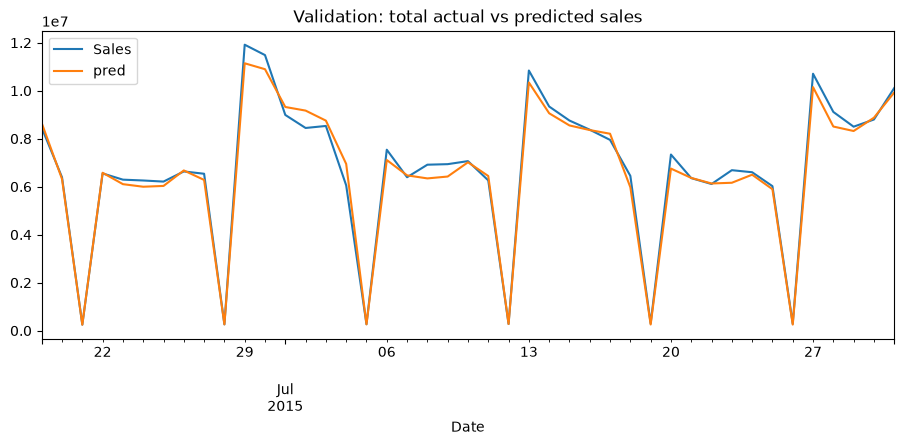

In [14]:
e = valid_df.assign(pred=pred_lgb)
e["ape"] = (e.Sales - e.pred).abs() / e.Sales
print(e.groupby("StoreType")["ape"].mean().round(3))
print(e.groupby("DayOfWeek")["ape"].mean().round(3))
print(e.groupby("Promo")["ape"].mean().round(3))
worst = e.groupby("Store")["ape"].mean().sort_values(ascending=False).head(10)
print(worst)
# predicted vs actual for the total across all stores, per day
tot = e.groupby("Date")[["Sales", "pred"]].sum()
tot.plot(figsize=(11, 4), title="Validation: total actual vs predicted sales")
plt.savefig("reports/figures/06_actual_vs_pred.png", dpi=150, bbox_inches="tight")

In [15]:
q_lo = lgb.LGBMRegressor(objective="quantile", alpha=0.1, n_estimators=600,
learning_rate=0.05, num_leaves=63, random_state=42)
q_hi = lgb.LGBMRegressor(objective="quantile", alpha=0.9, n_estimators=600,
learning_rate=0.05, num_leaves=63, random_state=42)
q_lo.fit(X_tr, y_tr)
q_hi.fit(X_tr, y_tr)
lo, hi = np.expm1(q_lo.predict(X_va)), np.expm1(q_hi.predict(X_va))
print("Coverage of 80%% band: %.1f%%" % (((valid_df.Sales >= lo) &
(valid_df.Sales <= hi)).mean() * 100))

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.021234 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3440
[LightGBM] [Info] Number of data points in the train set: 802942, number of used features: 26
[LightGBM] [Info] Start training from score 8.231642
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.016766 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3440
[LightGBM] [Info] Number of data points in the train set: 802942, number of used features: 26
[LightGBM] [Info] Start training from score 9.284891
Coverage of 80% band: 72.0%


In [5]:
import pandas as pd

app = pd.read_csv("app/app_data.csv", parse_dates=["Date"])
val_fc = valid_df[["Store", "Date"]].assign(Forecast2=pred_lgb.round(0))
app = app.merge(val_fc, on=["Store", "Date"], how="left")
app["Forecast"] = app["Forecast"].fillna(app["Forecast2"])
app = app.drop(columns="Forecast2")
app.to_csv("app/app_data.csv", index=False)

test = app[(app.Date >= "2015-06-19") & (app.Date < "2015-08-01")]
print(test.Forecast.notna().sum(), "test-period forecasts added")

41396 test-period forecasts added


In [7]:
import pandas as pd

e = valid_df[["Store", "Date", "Sales"]].assign(Forecast=pred_lgb)
e["ape"] = (e.Sales - e.Forecast).abs() / e.Sales * 100
by_store = e.groupby("Store")["ape"].mean().sort_values(ascending=False)

print("Median store error: %.1f%%" % by_store.median())
print("Stores with error above 15%%: %d of %d" % ((by_store > 15).sum(), len(by_store)))
print("Stores with error above 30%%: %d" % (by_store > 30).sum())
print("\nWorst 10 stores:")
print(by_store.head(10).round(1))

# does the app show the same forecasts as the notebook?
app = pd.read_csv("app/app_data.csv", parse_dates=["Date"])
m = e.merge(app[["Store", "Date", "Forecast"]], on=["Store", "Date"],
            suffixes=("_nb", "_app"))
print("\nLargest gap between notebook and app forecast:",
      (m.Forecast_nb - m.Forecast_app).abs().max())

Median store error: 8.0%
Stores with error above 15%: 30 of 1115
Stores with error above 30%: 2

Worst 10 stores:
Store
292     56.0
909     51.4
722     29.2
876     29.0
274     25.7
192     21.7
782     20.2
1073    19.5
534     19.3
286     19.0
Name: ape, dtype: float64

Largest gap between notebook and app forecast: 0.4999895135833867
